# CDS-level performance on CDS of at least 90 bp, across IoU thresholds and error rates

MetaGeneMark-2 cannot predict CDS shorter than 90 bp (its models set `$GENE_MIN_LENGTH 89`; its shortest prediction is 90 nt). For a fair comparison with MetaGeneMark-2, this notebook restricts **both** the ground truth and every model's predictions to CDS fragments of at least 90 bp (`end - start + 1 >= 90`, after merging indel-disrupted fragments with `get_full_cds`) and scores all models at one read length on all four test sets (error-free, typical, high and stress error rates), for IoU thresholds 0.5-1.0.

Matching is the greedy IoU matching of `cds_level_read_length_IoU_thresholds.ipynb` (same `get_full_cds` and disrupted-RF-aware `calculate_iou`, copied below; for error-free reads it reduces to the plain IoU). The IoU matrix of a read is computed once and matched at every threshold. Pooled scores over the TT11 test genomes, and separately over the 3 TT4 (*Mycoplasmataceae*) test genomes (separate figure, same y-axis; not in the LaTeX table); genome-level cluster bootstrap SE (1000 replicates, seed 42). With only 3 TT4 genomes, their SE is not meaningful and is not plotted.

In [1]:
import os
import pickle
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

sys.path.insert(0, '..')
from plot_config import MODEL_COLORS, MODEL_DISPLAY_NAMES, MODEL_MARKERS, FONT_SIZES

plt.rcParams.update(FONT_SIZES)

In [2]:
#project_root = "../../../.."
project_root = "/tmp/nrt204/FragmentPredictor"

read_length = 300
MIN_CDS_LENGTH = 90  # MetaGeneMark-2's shortest possible prediction
overlap_thresholds = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

#Load data if already processed; set to False to re-run data processing and overwrite cached results
LOAD_PROCESSED_DATA = False

test_sets = {
    "error_free": "without_errors",
    "typical": "with_errors_5e-06i_0.004s",
    "high": "with_errors_1.25e-05i_0.01s",
    "stress": "with_errors_3.75e-05i_0.03s",
}
test_set_labels = {"error_free": "Error-free", "typical": "Typical error", "high": "High error", "stress": "Stress error"}

models_per_set = {
    "error_free": ["fgs_complete", "prodigal", "metagenemark2", "deep_cds_no_errors"],
    **{s: ["fgs_complete", "fgs_illumina_5", "fgs_illumina_10", "prodigal", "metagenemark2",
           "deep_cds_no_errors", "deep_cds_substitution", "deep_cds_errors"] for s in ("typical", "high", "stress")},
}
all_models = models_per_set["typical"]

all_test_accessions = open(f"{project_root}/data/processed_data/genome_partitions/test_partition_accessions.txt").read().splitlines()
genome_info_df = pd.read_csv(f"{project_root}/data/processed_data/dataset_information/genomes_info_with_partitions.csv").set_index('accession')
tt4_families = ['Mycoplasmataceae']
tt11_accessions = [acc for acc in all_test_accessions
                   if not (acc in genome_info_df.index and genome_info_df.loc[acc, 'family'] in tt4_families)]
tt4_accessions = [acc for acc in all_test_accessions if acc not in tt11_accessions]
populations = {"tt11": tt11_accessions, "tt4": tt4_accessions}
print(f"{len(tt11_accessions)} TT11 and {len(tt4_accessions)} TT4 test genomes (of {len(all_test_accessions)})")

_script_name = "cds_level_min90bp_iou_by_error_rate"
_cache_dir = f"{project_root}/data/processed_data/report_results/with_errors/{_script_name}/{read_length}bp_min_{MIN_CDS_LENGTH}"


212 TT11 and 3 TT4 test genomes (of 215)


In [3]:
def get_full_cds(reads_dict):
    """Merge fragmented CDS annotations that belong to the same gene.

    When a CDS is split into multiple fragments (e.g. due to short fragment
    removal during preprocessing), this function reconnects them into a single
    CDS span using the cds_fragments_connection mapping. The merged CDS is
    labelled 'disrupted_rf' and replaces the individual fragments.

    The original per-fragment coordinates (each with its own RF label) are
    preserved as a 4th element so that calculate_iou can determine which
    positions within the disrupted span belong to which reading frame:
        [start, end, 'disrupted_rf', [(s1, e1, rf1), (s2, e2, rf2), ...]]

    Args:
        reads_dict: Dict mapping read names to dicts with 'cds_coords' (list of
            [start, end, rf] triplets) and 'cds_fragments_connection' (list of
            index groups indicating which fragments belong together).

    Returns:
        The modified reads_dict with fragmented CDS entries merged.
    """
    for read in reads_dict.keys():
        cds_fragments_connections = reads_dict[read]['cds_fragments_connection']
        cds_coords = reads_dict[read]['cds_coords']

        indices_to_remove = []
        
        for cds_frag_mapping in cds_fragments_connections:
            if len(cds_frag_mapping) > 1:
                # Postprocessing for testset due to how short fragments were removed
                if len(cds_fragments_connections) != cds_frag_mapping[0] + 1:
                    if len(cds_frag_mapping) == 1:
                        cds_frag_mapping = [cds_index - 1 for cds_index in cds_frag_mapping]
                
                elif len(cds_fragments_connections) == 1 and cds_frag_mapping == [0, 2]:
                    cds_frag_mapping = [0, 1]
                elif len(cds_fragments_connections) == 1 and cds_frag_mapping == [2, 3, 4]:
                    cds_frag_mapping = [0, 1, 2]
                
                start_cds_frag = cds_coords[min(cds_frag_mapping)][0]
                end_cds_frag = cds_coords[max(cds_frag_mapping)][1]

                # Preserve individual fragment coordinates sorted by start position.
                fragment_list = sorted(
                    [(cds_coords[i][0], cds_coords[i][1], cds_coords[i][2])
                     for i in cds_frag_mapping],
                    key=lambda f: f[0]
                )

                indices_to_remove += cds_frag_mapping
                
                assert start_cds_frag < end_cds_frag, "Something went wrong processing indel-induced error in sequence!"
                cds_coords.append([start_cds_frag, end_cds_frag, 'disrupted_rf', fragment_list])
                reads_dict[read]['cds_coords'] = cds_coords

        for index in sorted(indices_to_remove, reverse=True):
            cds_coords.pop(index)
    
    return reads_dict


def _get_rf_spans(coord):
    """Extract per-RF coordinate spans from a CDS coord entry.

    Args:
        coord: [start, end, rf] or [start, end, 'disrupted_rf', [(s,e,rf), ...]].

    Returns:
        Dict mapping rf_label -> list of (start, end) tuples.
    """
    if len(coord) == 4 and coord[2] == 'disrupted_rf':
        by_rf = {}
        for s, e, rf in coord[3]:
            by_rf.setdefault(rf, []).append((s, e))
        return by_rf
    else:
        return {coord[2]: [(coord[0], coord[1])]}


def _overlap(s1, e1, s2, e2):
    return max(0, min(e1, e2) - max(s1, s2))


def _total_span_length(spans_by_rf):
    return sum(e - s for spans in spans_by_rf.values() for s, e in spans)


def _rf_intersection(spans_a, spans_b):
    """Total coordinate overlap between two lists of (start, end) spans (same RF)."""
    total = 0
    for s1, e1 in spans_a:
        for s2, e2 in spans_b:
            total += _overlap(s1, e1, s2, e2)
    return total


def calculate_iou(coord1, coord2):
    """Calculate IoU between two CDS entries, disrupted-RF-aware.

    coord1 is the prediction; coord2 is the truth.  Handles five cases:

    1. Both single-RF, same RF: standard coordinate IoU.
    2. Both single-RF, different RF: returns 0.0.
    3. Pred=single-RF, truth=disrupted_rf:
       IoU = intersection(pred, truth's matching-RF sub-span)
             / union(pred, truth's matching-RF sub-span).
       Truth's non-matching RF sub-spans are NOT counted as FN — the prediction
       only claims to have found one RF of the gene.
    4. Pred=disrupted_rf, truth=single-RF:
       TP = intersection(pred's matching-RF sub-span, truth).
       All non-matching RF sub-spans of pred count as FP (model predicted an
       indel that is absent in the truth).
       IoU = TP / (|pred_total| + |truth| - TP).
    5. Both disrupted_rf:
       RF-by-RF fragment comparison merged into one IoU:
       IoU = sum(intersection_rf) / (|pred_total| + |truth_total| - sum(intersection_rf)).

    Args:
        coord1: Prediction — [start, end, rf] or
                [start, end, 'disrupted_rf', [(s, e, rf), ...]].
        coord2: Truth — same format as coord1.

    Returns:
        IoU value in [0.0, 1.0].
    """
    pred_disrupted = coord1[2] == 'disrupted_rf'
    truth_disrupted = coord2[2] == 'disrupted_rf'

    # Cases 1 & 2: both single-RF
    if not pred_disrupted and not truth_disrupted:
        if coord1[2] != coord2[2]:
            return 0.0
        inter = _overlap(coord1[0], coord1[1], coord2[0], coord2[1])
        if inter == 0:
            return 0.0
        union = (coord1[1] - coord1[0]) + (coord2[1] - coord2[0]) - inter
        return inter / union if union > 0 else 0.0

    pred_spans = _get_rf_spans(coord1)
    truth_spans = _get_rf_spans(coord2)

    # Case 3: pred=single-RF, truth=disrupted_rf
    # Evaluate pred only against the matching-RF sub-span of the truth.
    if not pred_disrupted and truth_disrupted:
        rf = coord1[2]
        if rf not in truth_spans:
            return 0.0
        pred_len = coord1[1] - coord1[0]
        truth_rf_len = sum(e - s for s, e in truth_spans[rf])
        inter = _rf_intersection([(coord1[0], coord1[1])], truth_spans[rf])
        denom = pred_len + truth_rf_len - inter
        return inter / denom if denom > 0 else 0.0

    # Case 4: pred=disrupted_rf, truth=single-RF
    # Non-matching RF sub-spans of pred are FP.
    if pred_disrupted and not truth_disrupted:
        rf = coord2[2]
        truth_len = coord2[1] - coord2[0]
        pred_total_len = _total_span_length(pred_spans)
        inter = 0
        if rf in pred_spans:
            inter = _rf_intersection(pred_spans[rf], [(coord2[0], coord2[1])])
        denom = pred_total_len + truth_len - inter
        return inter / denom if denom > 0 else 0.0

    # Case 5: both disrupted_rf — RF-by-RF fragment comparison
    all_rfs = set(pred_spans.keys()) | set(truth_spans.keys())
    pred_total_len = _total_span_length(pred_spans)
    truth_total_len = _total_span_length(truth_spans)
    total_inter = 0
    for rf in all_rfs:
        if rf in pred_spans and rf in truth_spans:
            total_inter += _rf_intersection(pred_spans[rf], truth_spans[rf])
    denom = pred_total_len + truth_total_len - total_inter
    return total_inter / denom if denom > 0 else 0.0


def keep_long_cds(coords, min_length=MIN_CDS_LENGTH):
    """CDS entries of at least min_length bp (end - start + 1); disrupted_rf entries by their merged span."""
    return [c for c in coords if c[1] - c[0] + 1 >= min_length]


def tp_per_threshold(predicted_coords, actual_coords, thresholds):
    """Greedy IoU matching (as find_matching_genes) at every threshold, from one IoU matrix per read.

    Each prediction, in order, is matched to the unmatched ground-truth CDS with the highest IoU,
    provided IoU >= threshold. Returns the number of matches per threshold.
    """
    if not predicted_coords or not actual_coords:
        return [0] * len(thresholds)
    iou = [[calculate_iou(p, a) for a in actual_coords] for p in predicted_coords]
    counts = []
    for threshold in thresholds:
        used_actual, tp = set(), 0
        for row in iou:
            best_iou, best_idx = 0.0, -1
            for idx, value in enumerate(row):
                if idx not in used_actual and value >= threshold and value > best_iou:
                    best_iou, best_idx = value, idx
            if best_idx != -1:
                used_actual.add(best_idx)
                tp += 1
        counts.append(tp)
    return counts

In [4]:
def load_testset(test_accession, data_type, project_root=project_root):
    """Ground truth (fragmented CDS merged via get_full_cds) and read names for one genome."""
    with open(f"{project_root}/data/processed_data/testset_processed/{data_type}/{test_accession}/testset_dict.pkl", "rb") as f:
        testset_dict = pickle.load(f)
    with open(f"{project_root}/data/processed_data/testset_processed/{data_type}/{test_accession}/read_names_list.pkl", "rb") as f:
        read_names_list = pickle.load(f)
    return read_names_list, get_full_cds(testset_dict)


def load_model_preds(test_accession, data_type, model_name, project_root=project_root):
    """Post-processed predictions of one model (fragmented CDS merged via get_full_cds)."""
    pp = f"{project_root}/data/processed_data/predictions/processed_predictions"
    deepcds_run = "full_model_all_genomes_seed_42_trained_final_8M_no_dropout"
    fgs_dir = data_type if data_type.startswith("without_errors") else f"{data_type}_complete"
    pred_paths = {
        "prodigal": f"{pp}/prodigal_preds/{data_type}/{test_accession}/model_preds_dict.pkl",
        "metagenemark2": f"{pp}/metagenemark2_preds/{data_type}/{test_accession}/model_preds_dict.pkl",
        "fgs_complete": f"{pp}/fgs_preds/{fgs_dir}/{test_accession}.pkl",
        "fgs_illumina_5": f"{pp}/fgs_preds/{data_type}_illumina_5/{test_accession}.pkl",
        "fgs_illumina_10": f"{pp}/fgs_preds/{data_type}_illumina_10/{test_accession}.pkl",
        "deep_cds_no_errors": f"{pp}/DeepCDS/model_without_errors/{data_type}/{deepcds_run}/{test_accession}/model_preds_dict.pkl",
        "deep_cds_substitution": f"{pp}/DeepCDS/model_with_substitution_errors/{data_type}/{deepcds_run}/{test_accession}/model_preds_dict.pkl",
        "deep_cds_errors": f"{pp}/DeepCDS/model_with_errors/{data_type}/{deepcds_run}/{test_accession}/model_preds_dict.pkl",
    }
    with open(pred_paths[model_name], "rb") as f:
        preds = pickle.load(f)
    return get_full_cds(preds)

# Count TP/FP/FN per genome

In [5]:
_cache_file = os.path.join(_cache_dir, "per_genome_counts.pkl")

# per_genome_counts[test_set][model][threshold][accession] = {'tp', 'fp', 'fn'} (TT11 and TT4 genomes)
per_genome_counts = {s: {m: {t: {} for t in overlap_thresholds} for m in models_per_set[s]} for s in test_sets}
if LOAD_PROCESSED_DATA and os.path.isfile(_cache_file):
    print(f"Loading pre-computed results from:\n  {_cache_file}")
    with open(_cache_file, "rb") as f:
        _cached = pickle.load(f)
    for s in test_sets:
        for m in models_per_set[s]:
            if m in _cached.get(s, {}):
                per_genome_counts[s][m] = _cached[s][m]

# Count only the (test set, genome) pairs with a model missing from the cache
_todo = {s: [a for a in tt11_accessions + tt4_accessions
             if any(a not in per_genome_counts[s][m][overlap_thresholds[0]] for m in models_per_set[s])]
         for s in test_sets}
if any(_todo.values()):
    for test_set, prefix in test_sets.items():
        data_type = f"{prefix}_{read_length}bp"
        for test_accession in tqdm(_todo[test_set], desc=data_type):
            try:
                read_names_list, testset_dict = load_testset(test_accession, data_type)
            except Exception as e:
                print(f"Error loading testset for {test_accession} ({data_type}): {e}")
                continue
            truth = {r: keep_long_cds(testset_dict.get(r, {}).get("cds_coords", [])) for r in read_names_list}
            n_truth = sum(len(c) for c in truth.values())
            for model in models_per_set[test_set]:
                if test_accession in per_genome_counts[test_set][model][overlap_thresholds[0]]:
                    continue
                try:
                    preds = load_model_preds(test_accession, data_type, model)
                except Exception as e:
                    print(f"Error loading {model} for {test_accession} ({data_type}): {e}")
                    continue
                tp, n_pred = np.zeros(len(overlap_thresholds), dtype=int), 0
                for read_name in read_names_list:
                    pred = keep_long_cds(preds.get(read_name, {}).get("cds_coords", []))
                    n_pred += len(pred)
                    tp += tp_per_threshold(pred, truth[read_name], overlap_thresholds)
                for t, tp_t in zip(overlap_thresholds, tp):
                    per_genome_counts[test_set][model][t][test_accession] = {
                        'tp': int(tp_t), 'fp': int(n_pred - tp_t), 'fn': int(n_truth - tp_t)}
    os.makedirs(_cache_dir, exist_ok=True)
    with open(_cache_file, "wb") as f:
        pickle.dump(per_genome_counts, f)
    print(f"Results saved to {_cache_dir}")

with_errors_3.75e-05i_0.03s_300bp: 100%|██████████| 215/215 [05:22<00:00,  1.50s/it]

Results saved to /tmp/nrt204/FragmentPredictor/data/processed_data/report_results/with_errors/cds_level_min90bp_iou_by_error_rate/300bp_min_90


# Pooled scores and genome-level cluster bootstrap SE

In [6]:
N_BOOTSTRAP = 1000
_rng = np.random.default_rng(42)


def pooled_scores(tp, fp, fn):
    """Pooled precision/recall/F1 from summed counts; array-safe, 0 where undefined."""
    p = np.divide(tp, tp + fp, out=np.zeros_like(tp, dtype=float), where=(tp + fp) > 0)
    r = np.divide(tp, tp + fn, out=np.zeros_like(tp, dtype=float), where=(tp + fn) > 0)
    f1 = np.divide(2 * p * r, p + r, out=np.zeros_like(tp, dtype=float), where=(p + r) > 0)
    return {'precision': p, 'recall': r, 'f1_score': f1}


rows = []
for population, accessions in populations.items():
  for test_set in test_sets:
    for model in models_per_set[test_set]:
        for t in overlap_thresholds:
            counts = {a: per_genome_counts[test_set][model][t][a] for a in accessions
                      if a in per_genome_counts[test_set][model][t]}
            arr = {k: np.array([c[k] for c in counts.values()], dtype=float) for k in ('tp', 'fp', 'fn')}
            point = pooled_scores(*(arr[k].sum() for k in ('tp', 'fp', 'fn')))
            idx = _rng.integers(0, len(counts), size=(N_BOOTSTRAP, len(counts)))
            boot = pooled_scores(*(arr[k][idx].sum(axis=1) for k in ('tp', 'fp', 'fn')))
            row = {'population': population, 'test_set': test_set, 'model': model, 'overlap': t, 'n_genomes': len(counts)}
            for metric in ('f1_score', 'precision', 'recall'):
                row[metric] = float(point[metric])
                row[f'{metric}_se'] = float(boot[metric].std(ddof=1))
            rows.append(row)
scores = pd.DataFrame(rows)
print(f"Genome-level cluster bootstrap: N={N_BOOTSTRAP} replicates, seed 42; "
      f"genomes per cell: {scores.groupby('population')['n_genomes'].unique().to_dict()}")
scores.pivot_table(index=['population', 'test_set', 'model'], columns='overlap', values='f1_score', sort=False).round(3)

Genome-level cluster bootstrap: N=1000 replicates, seed 42; genomes per cell: {'tt11': array([212]), 'tt4': array([3])}


overlap                                        0.5    0.6    0.7    0.8  \
population test_set   model                                               
tt11       error_free fgs_complete           0.934  0.932  0.927  0.919   
                      prodigal               0.963  0.962  0.959  0.954   
                      metagenemark2          0.936  0.932  0.926  0.913   
                      deep_cds_no_errors     0.990  0.989  0.988  0.986   
           typical    fgs_complete           0.923  0.918  0.909  0.895   
                      prodigal               0.952  0.948  0.941  0.931   
                      metagenemark2          0.925  0.918  0.907  0.889   
                      deep_cds_no_errors     0.983  0.979  0.975  0.968   
                      fgs_illumina_5         0.912  0.894  0.874  0.850   
                      fgs_illumina_10        0.909  0.889  0.866  0.839   
                      deep_cds_substitution  0.987  0.986  0.984  0.981   
                      deep_cds_errors        0.985  0.984  0.981  0.977   
           high       fgs_complete           0.901  0.884  0.866  0.843   
                      prodigal               0.930  0.916  0.899  0.881   
                      metagenemark2          0.901  0.883  0.863  0.837   
                      deep_cds_no_errors     0.968  0.957  0.943  0.928   
                      fgs_illumina_5         0.896  0.870  0.842  0.810   
                      fgs_illumina_10        0.894  0.867  0.837  0.803   
                      deep_cds_substitution  0.984  0.982  0.979  0.974   
                      deep_cds_errors        0.983  0.980  0.977  0.971   
           stress     fgs_complete           0.831  0.788  0.742  0.700   
                      prodigal               0.860  0.821  0.778  0.738   
                      metagenemark2          0.829  0.784  0.737  0.691   
                      deep_cds_no_errors     0.919  0.883  0.845  0.807   
                      fgs_illumina_5         0.843  0.794  0.744  0.694   
                      fgs_illumina_10        0.844  0.797  0.746  0.694   
                      deep_cds_substitution  0.971  0.966  0.958  0.946   
                      deep_cds_errors        0.971  0.965  0.957  0.945   
tt4        error_free fgs_complete           0.748  0.684  0.629  0.581   
                      prodigal               0.980  0.978  0.977  0.974   
                      metagenemark2          0.739  0.677  0.622  0.575   
                      deep_cds_no_errors     0.993  0.992  0.991  0.990   
           typical    fgs_complete           0.736  0.672  0.616  0.563   
                      prodigal               0.964  0.959  0.953  0.942   
                      metagenemark2          0.727  0.665  0.610  0.558   
                      deep_cds_no_errors     0.985  0.984  0.981  0.974   
                      fgs_illumina_5         0.846  0.792  0.731  0.657   
                      fgs_illumina_10        0.855  0.805  0.746  0.668   
                      deep_cds_substitution  0.987  0.985  0.984  0.982   
                      deep_cds_errors        0.986  0.984  0.981  0.978   
           high       fgs_complete           0.714  0.640  0.576  0.520   
                      prodigal               0.939  0.920  0.902  0.882   
                      metagenemark2          0.705  0.633  0.571  0.515   
                      deep_cds_no_errors     0.973  0.964  0.954  0.943   
                      fgs_illumina_5         0.829  0.768  0.703  0.627   
                      fgs_illumina_10        0.840  0.781  0.719  0.639   
                      deep_cds_substitution  0.984  0.982  0.980  0.977   
                      deep_cds_errors        0.983  0.980  0.978  0.973   
           stress     fgs_complete           0.650  0.558  0.477  0.416   
                      prodigal               0.856  0.805  0.754  0.710   
                      metagenemark2          0.639  0.552  0.472  0.412   
                      dee

# F1 as a function of the IoU threshold, per test set (TT11 and TT4 as separate figures)

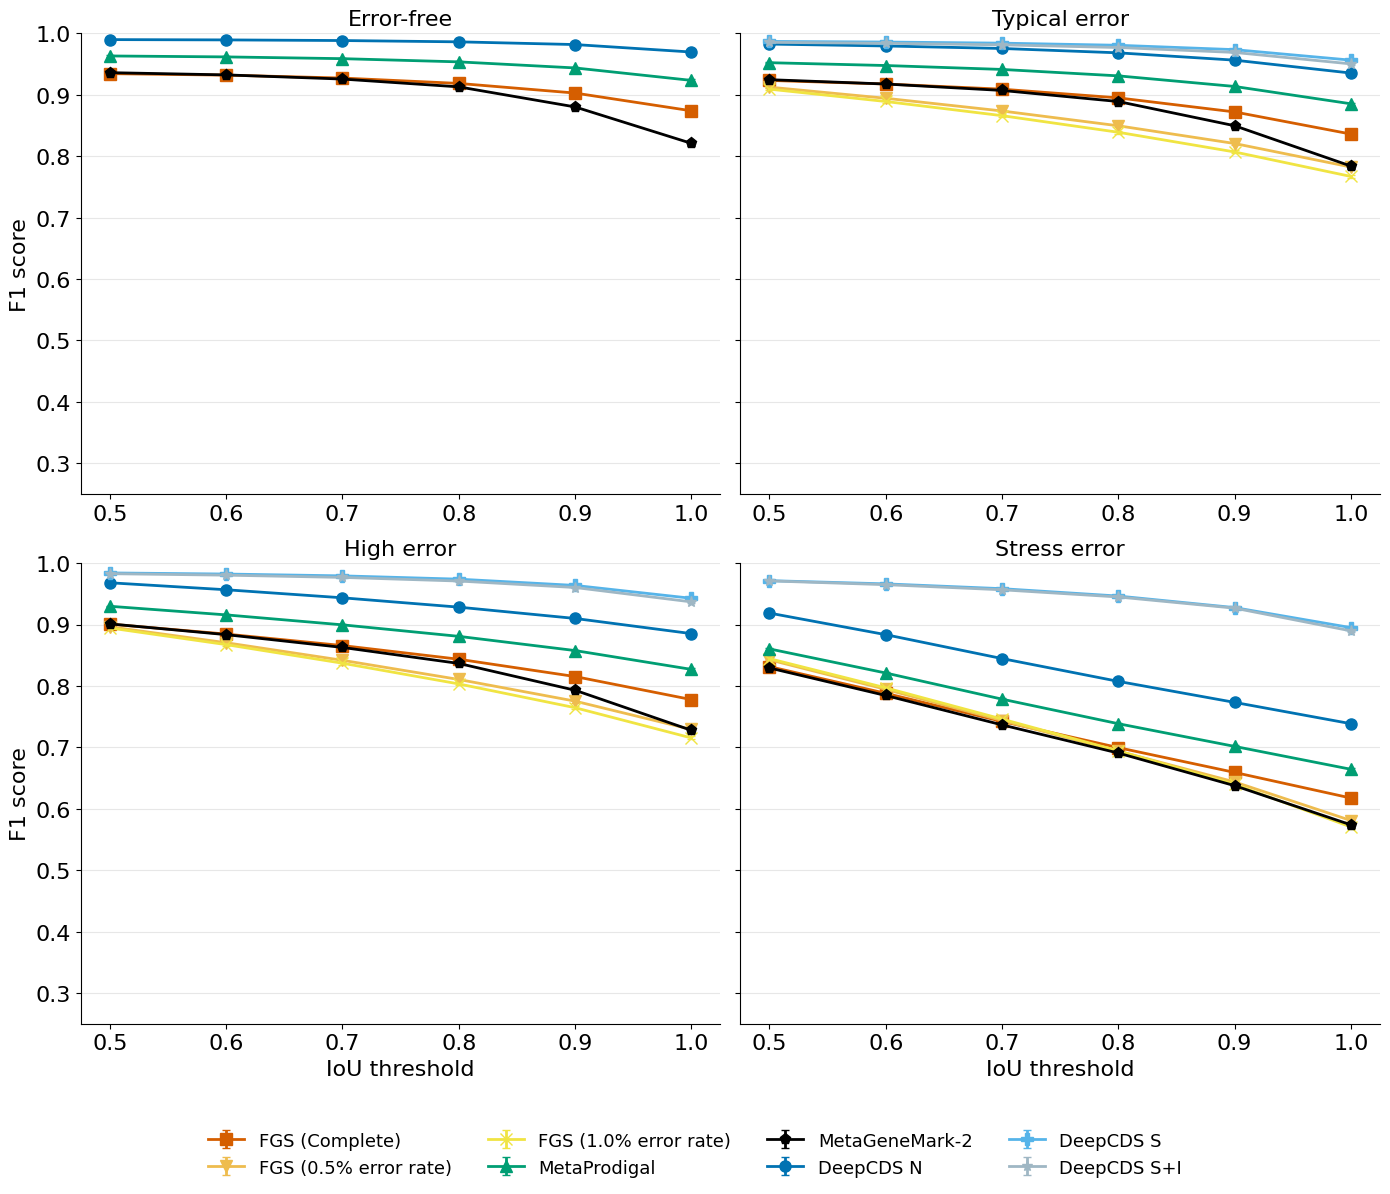

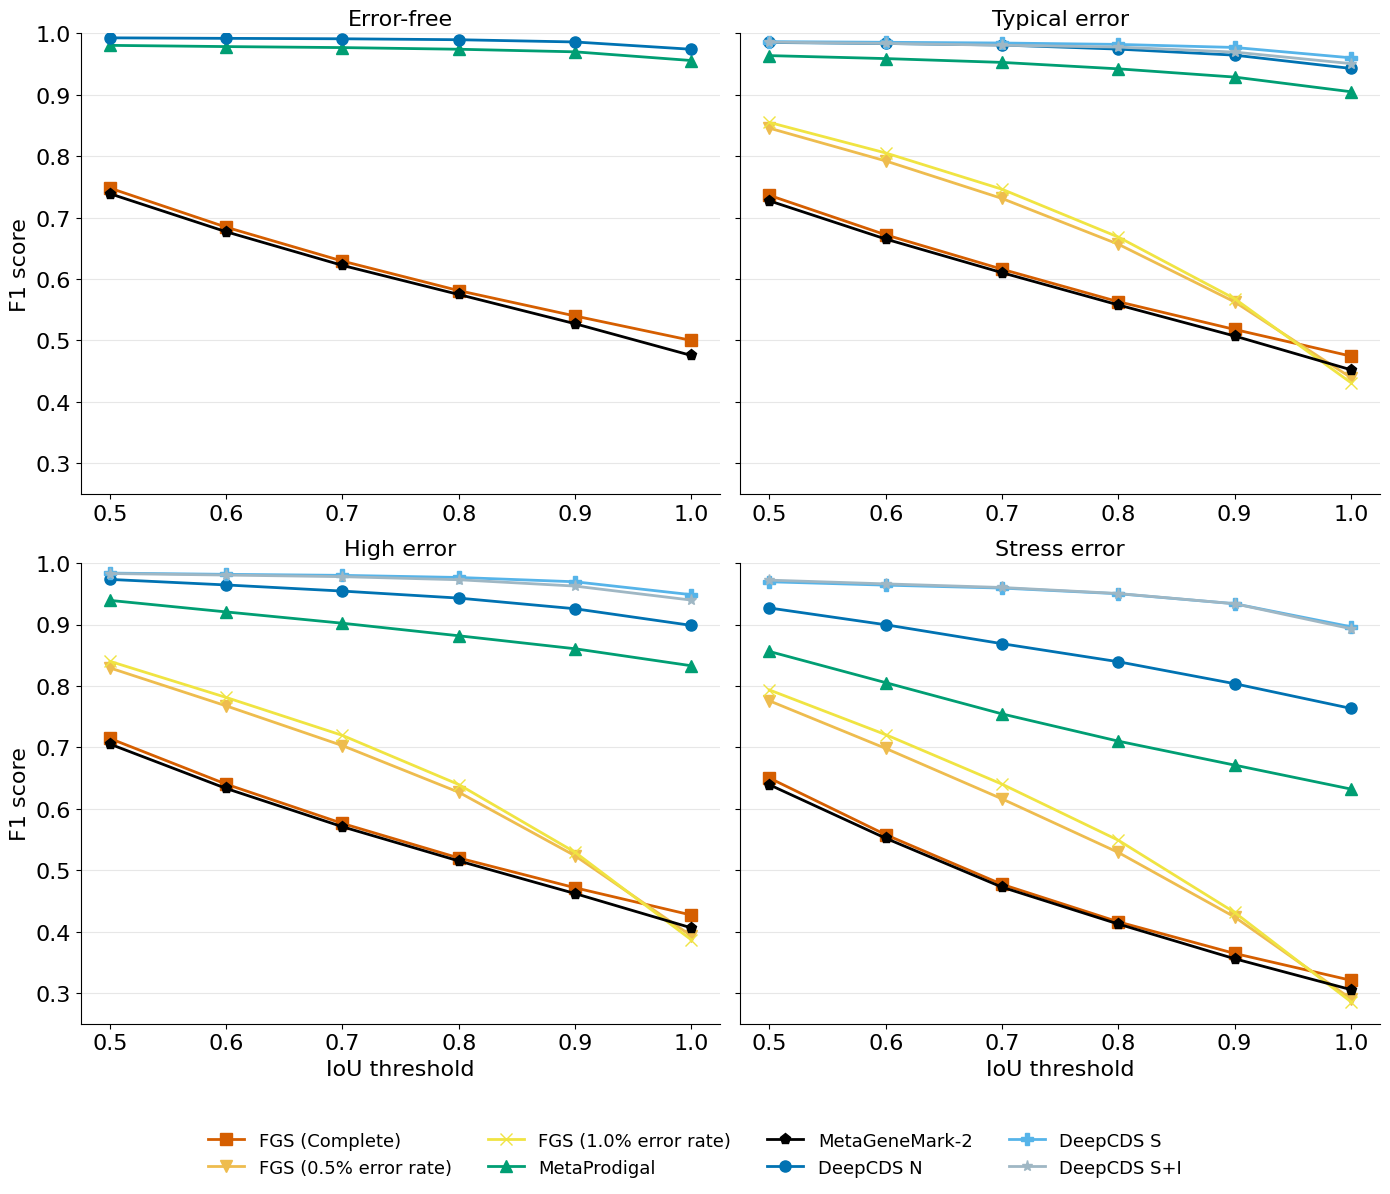

In [9]:
# One figure per population, same y-axis: TT11 (± SE) and TT4 (3 genomes, no SE)
_ylim = (np.floor(20 * (scores['f1_score'] - scores['f1_score_se']).min()) / 20, 1.0)


def plot_f1_by_iou(population, file_suffix=""):
    show_se = population == 'tt11'
    fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharey=True)
    axes = axes.flatten()
    for ax, test_set in zip(axes, test_sets):
        for model in models_per_set[test_set]:
            d = scores[(scores.population == population) & (scores.test_set == test_set) & (scores.model == model)]
            ax.errorbar(d['overlap'], d['f1_score'], yerr=d['f1_score_se'] if show_se else None, color=MODEL_COLORS[model],
                        marker=MODEL_MARKERS[model], markersize=8, linewidth=2, capsize=3, label=MODEL_DISPLAY_NAMES[model])
        ax.set_title(test_set_labels[test_set])
        ax.set_xticks(overlap_thresholds)
        ax.set_ylim(*_ylim)
        ax.grid(axis='y', alpha=0.3)
        ax.spines[['top', 'right']].set_visible(False)
    for ax in axes[2:]:
        ax.set_xlabel('IoU threshold')
    for ax in axes[::2]:
        ax.set_ylabel('F1 score')
    handles, labels = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.09))
    fig.tight_layout()
    plt.savefig(f"cds_level_f1_by_iou_min{MIN_CDS_LENGTH}bp_{read_length}bp{file_suffix}.png", dpi=500, bbox_inches='tight')
    plt.show()


plot_f1_by_iou('tt11')           # 212 TT11 genomes, ± genome-level cluster bootstrap SE
plot_f1_by_iou('tt4', '_TT4')    # 3 TT4 (Mycoplasmataceae) genomes, no SE


# LaTeX table: F1, sensitivity and precision at IoU 0.5, 0.8 and 1

In [8]:
table_thresholds = [0.5, 0.8, 1.0]
metrics_order = [('f1_score', 'F1 Score'), ('recall', 'Sensitivity'), ('precision', 'Precision')]


def _latex_escape(text):
    """Escape LaTeX specials in a model display name (e.g. the % of the FGS models)."""
    for _char in ('&', '%', '#', '_'):
        text = text.replace(_char, '\\' + _char)
    return text


def build_latex_table(show_std):
    """Rows = models, columns = test set x IoU threshold; best point estimate per column in bold.

    show_std: True  -> every cell reads 'estimate $\\pm$ SE' (genome-level cluster bootstrap SE);
              False -> point estimates only, with each model's SE range in the caption.
    """
    cols = [(s, t) for s in test_sets for t in table_thresholds]
    n_cols = len(cols)
    lines = [r'\begin{table}[ht]', r'\centering', r'\footnotesize',
             rf'\begin{{tabular}}{{l{"c" * n_cols}}}', r'\toprule',
             ' & ' + ' & '.join(rf'\multicolumn{{{len(table_thresholds)}}}{{c}}{{{test_set_labels[s]}}}' for s in test_sets) + r' \\',
             'IoU & ' + ' & '.join(f'{t:g}' for _, t in cols) + r' \\']
    value = scores[scores.population == 'tt11'].set_index(['test_set', 'model', 'overlap'])
    for metric, label in metrics_order:
        lines += [r'\midrule', rf'\multicolumn{{{1 + n_cols}}}{{l}}{{\textbf{{{label}}}}} \\', r'\midrule']
        best = {c: max(value.loc[(c[0], m, c[1]), metric] for m in models_per_set[c[0]]) for c in cols}
        for model in all_models:
            cells = []
            for s, t in cols:
                if model not in models_per_set[s]:
                    cells.append('--')
                    continue
                v = value.loc[(s, model, t), metric]
                cell = rf'\textbf{{{v:.3f}}}' if v == best[(s, t)] else f'{v:.3f}'
                if show_std:
                    cell += f" $\\pm$ {value.loc[(s, model, t), f'{metric}_se']:.3f}"
                cells.append(cell)
            lines.append(f'{_latex_escape(MODEL_DISPLAY_NAMES[model])} & ' + ' & '.join(cells) + r' \\')
    se = scores[scores.population == 'tt11'].groupby('model')[[f'{m}_se' for m, _ in metrics_order]].agg(['min', 'max'])
    se_ranges = '; '.join(
        f"{_latex_escape(MODEL_DISPLAY_NAMES[m])} {se.loc[m].xs('min', level=1).min():.3f}--{se.loc[m].xs('max', level=1).max():.3f}"
        for m in all_models)
    lines += [r'\bottomrule', r'\end{tabular}',
              rf'\caption{{TODO: WRITE CAPTION. CDS-level performance at {read_length}bp on CDS of at least {MIN_CDS_LENGTH}bp '
              rf'(ground truth and predictions), the shortest CDS MetaGeneMark-2 can predict, for IoU thresholds '
              rf'{", ".join(f"{t:g}" for t in table_thresholds)}. Pooled over the TT11 test genomes; best score per column in bold. '
              + (r'$\pm$ is the genome-level cluster bootstrap standard error (1000 replicates, resampling test genomes with replacement).'
                 if show_std else
                 rf'Across all cells, the genome-level cluster bootstrap standard error spans, per model: {se_ranges}.') + '}',
              rf'\label{{tab:cds_min{MIN_CDS_LENGTH}bp_iou_error_rates_{read_length}bp{"" if show_std else "_no_se"}}}', r'\end{table}']
    return '\n'.join(lines)


print('=' * 30, 'WITH per-cell SE', '=' * 30)
print(build_latex_table(show_std=True))
print()
print('=' * 30, 'WITHOUT per-cell SE (ranges in caption)', '=' * 30)
print(build_latex_table(show_std=False))

============================== WITH per-cell SE ==============================
\begin{table}[ht]
\centering
\footnotesize
\begin{tabular}{lcccccccccccc}
\toprule
 & \multicolumn{3}{c}{Error-free} & \multicolumn{3}{c}{Typical error} & \multicolumn{3}{c}{High error} & \multicolumn{3}{c}{Stress error} \\
IoU & 0.5 & 0.8 & 1 & 0.5 & 0.8 & 1 & 0.5 & 0.8 & 1 & 0.5 & 0.8 & 1 \\
\midrule
\multicolumn{13}{l}{\textbf{F1 Score}} \\
\midrule
FGS (Complete) & 0.934 $\pm$ 0.002 & 0.919 $\pm$ 0.002 & 0.874 $\pm$ 0.002 & 0.923 $\pm$ 0.002 & 0.895 $\pm$ 0.002 & 0.836 $\pm$ 0.002 & 0.901 $\pm$ 0.002 & 0.843 $\pm$ 0.002 & 0.778 $\pm$ 0.002 & 0.831 $\pm$ 0.002 & 0.700 $\pm$ 0.003 & 0.617 $\pm$ 0.003 \\
FGS (0.5\% error rate) & -- & -- & -- & 0.912 $\pm$ 0.002 & 0.850 $\pm$ 0.002 & 0.782 $\pm$ 0.002 & 0.896 $\pm$ 0.002 & 0.810 $\pm$ 0.002 & 0.729 $\pm$ 0.002 & 0.843 $\pm$ 0.002 & 0.694 $\pm$ 0.003 & 0.581 $\pm$ 0.003 \\
FGS (1.0\% error rate) & -- & -- & -- & 0.909 $\pm$ 0.002 & 0.839 $\pm$ 0.002 & 0.767 $